In [11]:
!pip install -q ucimlrepo

In [12]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Carregando o dataset PhiUSIIL
phishing = fetch_ucirepo(id=967)

# Atributos e variável-alvo
X = phishing.data.features
y = phishing.data.targets

# Visualizar as dimensões
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

# Visualizar os primeiros registros
display(X.head())

Dimensões de X: (235795, 54)
Dimensões de y: (235795, 1)


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,1,0,0,1,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,0,1,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,0,1,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,0,1,1,1,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,1,0,1,244,15,34,72,1,85


In [13]:
# Identificar colunas disponíveis
print(X.columns.tolist())

# Verificar valores ausentes
print(X.isnull().sum())

# Distribuição das classes
print(y.value_counts())

['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']
URL                           0
URLLength                     0
Domain                        0
Domain

Verificar duplicatas e preparar a base

In [14]:
# Criar um DataFrame com URLs e rótulos
df = pd.DataFrame({
    "URL": X["URL"],
    "label": y["label"]
})

print("Total de registros:", len(df))

print("URLs únicas:", df["URL"].nunique())

print("URLs duplicadas:", df["URL"].duplicated().sum())

print("Rótulos ausentes:", df["label"].isnull().sum())

# Verificar URLs associadas a classes diferentes
conflitos = df.groupby("URL")["label"].nunique()

print(
    "URLs com rótulos conflitantes:",
    (conflitos > 1).sum()
)

display(df.head())

Total de registros: 235795
URLs únicas: 235370
URLs duplicadas: 425
Rótulos ausentes: 0
URLs com rótulos conflitantes: 0


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


In [15]:
# Remover URLs duplicadas
df = df.drop_duplicates(subset=["URL"]).copy()

# Reorganizar os índices
df = df.reset_index(drop=True)

print("Total após limpeza:", len(df))

print("\nDistribuição das classes:")
print(df["label"].value_counts())

Total após limpeza: 235370

Distribuição das classes:
label
1    134850
0    100520
Name: count, dtype: int64


# Preparação das features

In [16]:
!pip install -q tldextract

In [17]:
from urllib.parse import urlsplit
import ipaddress
import tldextract # identifica corretamente as partes de um dominio

# Utiliza a lista de sufixos incluída no pacote, sem precisar consultar a internet.
extrator_tld = tldextract.TLDExtract(
    suffix_list_urls=()
)

def extrair_features(url):

    url = str(url).strip() # strip remove espaços em branco e quebras de linha

    # Separar os componentes da URL
    partes = urlsplit(url)

    dominio = partes.hostname or ""

    # Identificar domínio, sufixo e subdomínios
    info_dominio = extrator_tld(dominio)

    # Verificar se o domínio é um endereço IP
    try:
        ipaddress.ip_address(dominio) # interpreta texto como ipv4 ou ipv6
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    # Contar subdomínios
    subdominios = (
        info_dominio.subdomain.split(".")
        if info_dominio.subdomain
        else []
    )

    # Contar letras e dígitos
    num_letras = sum(c.isalpha() for c in url)
    num_digitos = sum(c.isdigit() for c in url)

    tamanho_url = len(url)

    # Evitar divisão por zero
    if tamanho_url > 0:
        proporcao_letras = num_letras / tamanho_url
        proporcao_digitos = num_digitos / tamanho_url
    else:
        proporcao_letras = 0
        proporcao_digitos = 0

    features = {
        "URLLength": tamanho_url,
        "DomainLength": len(dominio),
        "IsDomainIP": is_domain_ip,
        "TLDLength": len(info_dominio.suffix),
        "NoOfSubDomain": len(subdominios),
        "NoOfLetters": num_letras,
        "LetterRatio": proporcao_letras,
        "NoOfDigits": num_digitos,
        "DigitRatio": proporcao_digitos,
        "NoOfDots": url.count("."),
        "NoOfHyphens": url.count("-"),
        "NoOfEquals": url.count("="),
        "NoOfQMark": url.count("?"),
        "NoOfAmpersand": url.count("&"),
        "NoOfAt": url.count("@"),
        "IsHTTPS": int(partes.scheme.lower() == "https")
    }

    return features

Atenção: não estamos copiando os valores das colunas originais do PhiUSIIL. Estamos recalculando todas as características diretamente das URLs. Isso garante que nosso Flask possa reproduzir o mesmo processamento.

In [18]:
url_teste = "https://www.exemplo.com.br/login?id=123"

features = extrair_features(url_teste)

for nome, valor in features.items():
    print(f"{nome}: {valor}")

print("Quantidade de features:", len(url_teste))

URLLength: 39
DomainLength: 18
IsDomainIP: 0
TLDLength: 6
NoOfSubDomain: 1
NoOfLetters: 27
LetterRatio: 0.6923076923076923
NoOfDigits: 3
DigitRatio: 0.07692307692307693
NoOfDots: 3
NoOfHyphens: 0
NoOfEquals: 1
NoOfQMark: 1
NoOfAmpersand: 0
NoOfAt: 0
IsHTTPS: 1
Quantidade de features: 39


# Divisão dos Dados

In [19]:
from sklearn.model_selection import train_test_split

# Separação da base limpa
df_dev, df_teste = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

print("Desenvolvimento:", df_dev.shape)
print("Teste:", df_teste.shape)

Desenvolvimento: (188296, 2)
Teste: (47074, 2)


In [20]:
df_treino, _ = train_test_split(
    df_dev,
    train_size=20000,
    stratify=df_dev["label"],
    random_state=42
)

print("Treinamento:", df_treino.shape)

print("\nDistribuição das classes:")
print(df_treino["label"].value_counts())

Treinamento: (20000, 2)

Distribuição das classes:
label
1    11459
0     8541
Name: count, dtype: int64


In [21]:
import pandas as pd

# Extrair características das URLs de treinamento
X_treino = pd.DataFrame(
    df_treino["URL"].apply(extrair_features).tolist()
)

# Rótulos correspondentes
y_treino = df_treino["label"].reset_index(drop=True)

print("X_treino:", X_treino.shape)
print("y_treino:", y_treino.shape)

display(X_treino.head())

X_treino: (20000, 16)
y_treino: (20000,)


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,NoOfLetters,LetterRatio,NoOfDigits,DigitRatio,NoOfDots,NoOfHyphens,NoOfEquals,NoOfQMark,NoOfAmpersand,NoOfAt,IsHTTPS
0,30,23,0,3,1,25,0.833333,0,0.000000,2,0,0,0,0,0,0
1,21,13,0,5,1,15,0.714286,0,0.000000,3,0,0,0,0,0,1
2,27,19,0,2,1,22,0.814815,0,0.000000,2,0,0,0,0,0,1
3,27,19,0,6,1,21,0.777778,0,0.000000,3,0,0,0,0,0,1
4,41,32,0,3,1,21,0.512195,12,0.292683,2,2,0,0,0,0,1


In [22]:
X_teste = pd.DataFrame(
    df_teste["URL"].apply(extrair_features).tolist()
)

y_teste = df_teste["label"].reset_index(drop=True)

print("X_teste:", X_teste.shape)
print("y_teste:", y_teste.shape)

X_teste: (47074, 16)
y_teste: (47074,)


In [23]:
# Verificar se as colunas são iguais
print(
    "Mesmas features:",
    X_treino.columns.equals(X_teste.columns)
)

# Verificar valores ausentes
print(
    "Valores ausentes no treino:",
    X_treino.isnull().sum().sum()
)

print(
    "Valores ausentes no teste:",
    X_teste.isnull().sum().sum()
)

# Verificar tipos dos atributos
print("\nTipos de dados:")
print(X_treino.dtypes)

# Verificar sobreposição exata de URLs
urls_treino = set(df_treino["URL"])
urls_teste = set(df_teste["URL"])

print(
    "\nURLs repetidas entre treino e teste:",
    len(urls_treino.intersection(urls_teste))
)

Mesmas features: True
Valores ausentes no treino: 0
Valores ausentes no teste: 0

Tipos de dados:
URLLength          int64
DomainLength       int64
IsDomainIP         int64
TLDLength          int64
NoOfSubDomain      int64
NoOfLetters        int64
LetterRatio      float64
NoOfDigits         int64
DigitRatio       float64
NoOfDots           int64
NoOfHyphens        int64
NoOfEquals         int64
NoOfQMark          int64
NoOfAmpersand      int64
NoOfAt             int64
IsHTTPS            int64
dtype: object

URLs repetidas entre treino e teste: 0


# Implementação de Modelos

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(
            max_iter=500,
            early_stopping=True,
            random_state=42
        ))
    ])
}

In [25]:
parametros = {
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"]
    },

    "Decision Tree": {
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_split": [2, 10]
    },

    "Naive Bayes": {
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
    },

    "MLP": {
        "classifier__hidden_layer_sizes": [(32,), (32, 16)],
        "classifier__alpha": [0.0001, 0.01]
    }
}

# Treino com Conjunto de Amostra (20mil registros)

In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_busca = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

melhores_modelos = {}
resultados_busca = {}

for nome, pipeline in models.items():

    print(f"\nOtimizando {nome}...")

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros[nome],
        scoring="f1_macro",
        cv=cv_busca,
        n_jobs=-1
    )

    grid.fit(X_treino, y_treino)

    melhores_modelos[nome] = grid.best_estimator_
    resultados_busca[nome] = grid

    print("Melhores parâmetros:", grid.best_params_)
    print("Melhor F1 macro:", round(grid.best_score_, 4))


Otimizando KNN...
Melhores parâmetros: {'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Melhor F1 macro: 0.9872

Otimizando Decision Tree...
Melhores parâmetros: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2}
Melhor F1 macro: 0.9893

Otimizando Naive Bayes...
Melhores parâmetros: {'classifier__var_smoothing': 1e-07}
Melhor F1 macro: 0.8961

Otimizando MLP...
Melhores parâmetros: {'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (32, 16)}
Melhor F1 macro: 0.9935


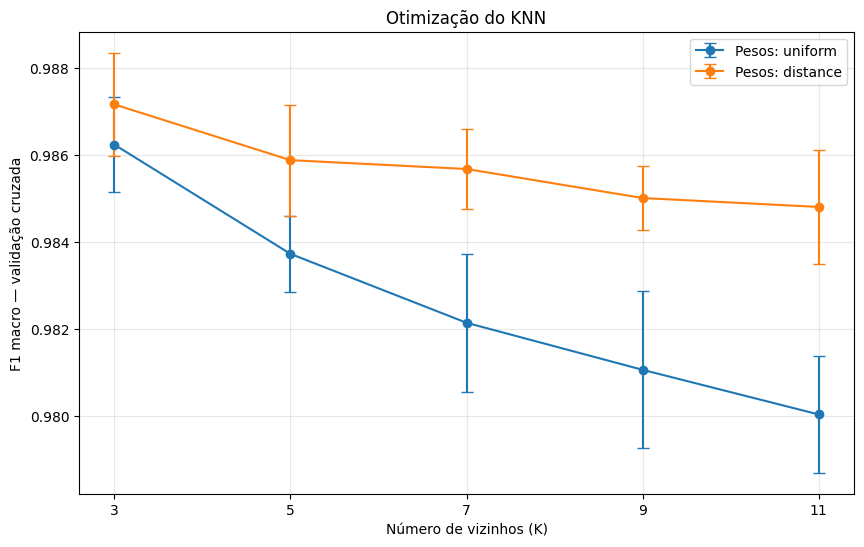

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

df_knn = pd.DataFrame(
    resultados_busca["KNN"].cv_results_
)

plt.figure(figsize=(10, 6))

for pesos in ["uniform", "distance"]:

    dados = df_knn[
        df_knn["param_classifier__weights"] == pesos
    ].copy()

    dados = dados.sort_values(
        "param_classifier__n_neighbors"
    )

    plt.errorbar(
        dados["param_classifier__n_neighbors"].astype(int),
        dados["mean_test_score"],
        yerr=dados["std_test_score"],
        marker="o",
        capsize=4,
        label=f"Pesos: {pesos}"
    )

plt.title("Otimização do KNN")
plt.xlabel("Número de vizinhos (K)")
plt.ylabel("F1 macro — validação cruzada")
plt.xticks([3, 5, 7, 9, 11])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
from sklearn.model_selection import cross_validate
import pandas as pd

cv_avaliacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

resumo = []

for nome, modelo in melhores_modelos.items():

    scores = cross_validate(
        modelo,
        X_treino,
        y_treino,
        cv=cv_avaliacao,
        scoring=scoring,
        n_jobs=-1
    )

    linha = {"Algoritmo": nome}

    for metrica in scoring:
        valores = scores[f"test_{metrica}"]

        linha[metrica] = valores.mean()
        linha[f"{metrica}_std"] = valores.std()

    resumo.append(linha)

df_cv = pd.DataFrame(resumo)

display(df_cv.round(4))

,Algoritmo,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std
0,KNN,0.9880,0.0013,0.9884,0.0013,0.9871,0.0014,0.9877,0.0013
1,Decision Tree,0.9905,0.0018,0.9905,0.0016,0.9901,0.0020,0.9903,0.0018
2,Naive Bayes,0.9020,0.0047,0.9232,0.0038,0.8865,0.0055,0.8963,0.0052
3,MLP,0.9944,0.0009,0.9947,0.0008,0.9937,0.0011,0.9942,0.0009


Validação cruzada e os hiperparametros foram definidos com amostra de 20 mil registros.

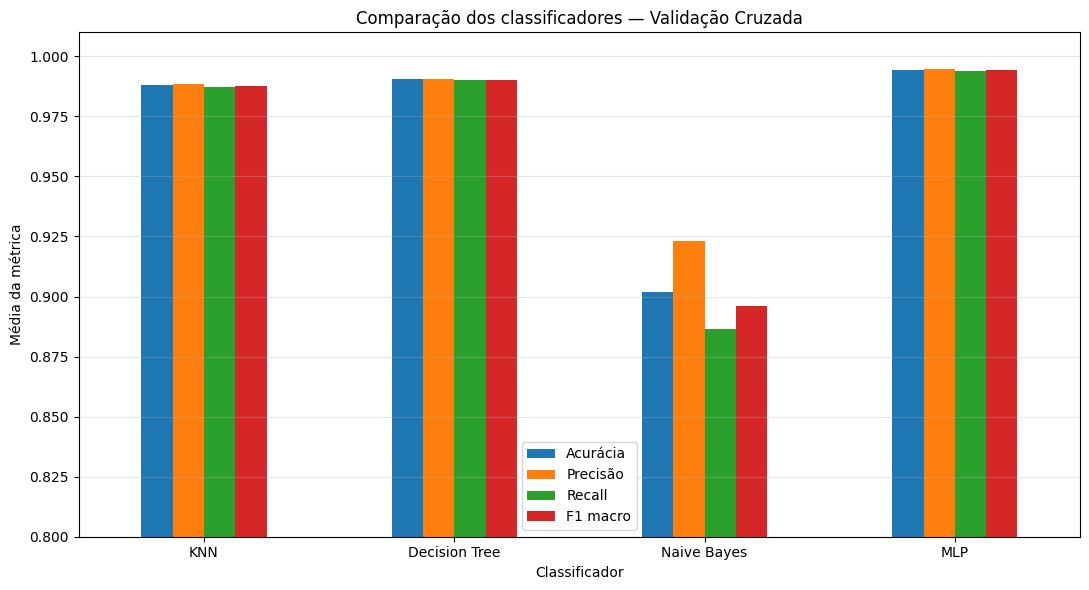

In [38]:
import matplotlib.pyplot as plt

metricas = ["accuracy", "precision", "recall", "f1"]

ax = df_cv.set_index("Algoritmo")[metricas].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0.80, 1.01),
    rot=0
)

plt.title("Comparação dos classificadores — Validação Cruzada")
plt.xlabel("Classificador")
plt.ylabel("Média da métrica")
plt.legend(["Acurácia", "Precisão", "Recall", "F1 macro"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Treinamento definitivo com Conjunto de Desenvolvimento (188mil registros)

In [29]:
X_dev = pd.DataFrame(
    df_dev["URL"].apply(extrair_features).tolist()
)

y_dev = df_dev["label"].reset_index(drop=True)

print("X_dev:", X_dev.shape)
print("y_dev:", y_dev.shape)

X_dev: (188296, 16)
y_dev: (188296,)


In [30]:
from sklearn.base import clone
import time

modelos_finais = {}
tempos_treinamento = {}

for nome, modelo in melhores_modelos.items():

    print(f"\nTreinando {nome}...")

    inicio = time.time()

    modelo_final = clone(modelo)
    modelo_final.fit(X_dev, y_dev)

    tempo = time.time() - inicio

    modelos_finais[nome] = modelo_final
    tempos_treinamento[nome] = tempo

    print(f"Treinamento concluído em {tempo:.2f} segundos")


Treinando KNN...
Treinamento concluído em 0.08 segundos

Treinando Decision Tree...
Treinamento concluído em 0.39 segundos

Treinando Naive Bayes...
Treinamento concluído em 0.10 segundos

Treinando MLP...
Treinamento concluído em 16.30 segundos


# Avaliação final dos classificadores

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import time

resultados_teste = []
previsoes = {}

for nome, modelo in modelos_finais.items():

    print(f"Avaliando {nome}...")

    inicio = time.time()

    y_pred = modelo.predict(X_teste)

    tempo = time.time() - inicio

    previsoes[nome] = y_pred

    resultados_teste.append({
        "Algoritmo": nome,
        "Acurácia": accuracy_score(y_teste, y_pred),
        "Precisão macro": precision_score(
            y_teste, y_pred, average="macro"
        ),
        "Recall macro": recall_score(
            y_teste, y_pred, average="macro"
        ),
        "F1 macro": f1_score(
            y_teste, y_pred, average="macro"
        ),
        "Recall phishing": recall_score(
            y_teste, y_pred, pos_label=0
        ),
        "Tempo previsão (s)": tempo
    })

df_resultados_teste = pd.DataFrame(resultados_teste)

display(
    df_resultados_teste.sort_values(
        "F1 macro",
        ascending=False
    ).round(4)
)

Avaliando KNN...
Avaliando Decision Tree...
Avaliando Naive Bayes...
Avaliando MLP...


,Algoritmo,Acurácia,Precisão macro,Recall macro,F1 macro,Recall phishing,Tempo previsão (s)
3,MLP,0.9957,0.9961,0.9951,0.9956,0.9910,0.0710
1,Decision Tree,0.9951,0.9954,0.9947,0.9950,0.9916,0.0124
0,KNN,0.9946,0.9949,0.9939,0.9944,0.9898,77.5121
2,Naive Bayes,0.9025,0.9238,0.8870,0.8968,0.7805,0.0206


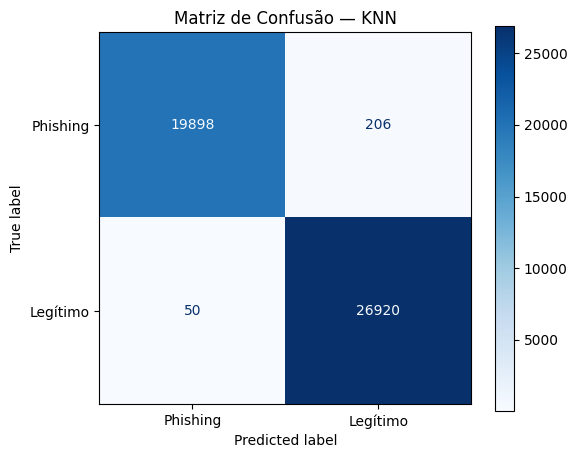

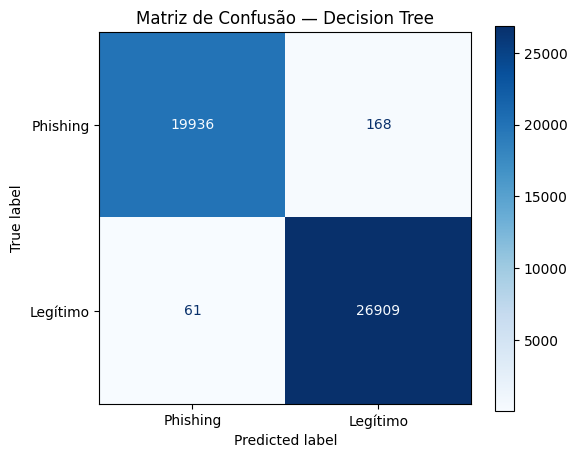

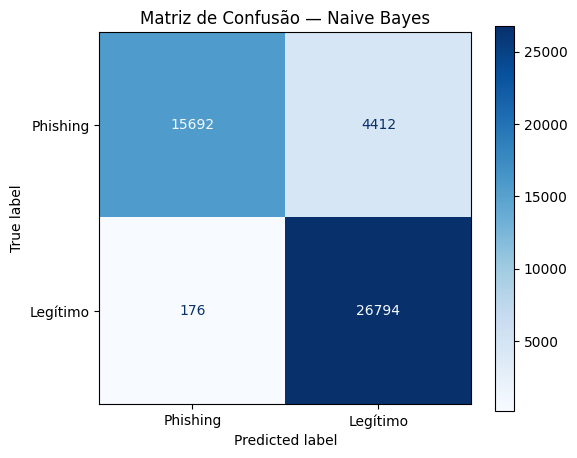

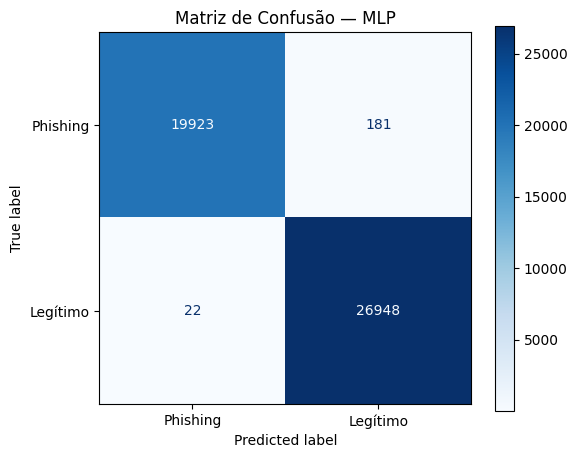

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for nome, y_pred in previsoes.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        y_pred,
        labels=[0, 1],
        display_labels=["Phishing", "Legítimo"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"Matriz de Confusão — {nome}")

    plt.show()

In [33]:
from sklearn.metrics import classification_report

for nome, y_pred in previsoes.items():

    print(f"\n===== {nome} =====")

    print(
        classification_report(
            y_teste,
            y_pred,
            labels=[0, 1],
            target_names=["Phishing", "Legítimo"],
            digits=4
        )
    )


===== KNN =====
              precision    recall  f1-score   support

    Phishing     0.9975    0.9898    0.9936     20104
    Legítimo     0.9924    0.9981    0.9953     26970

    accuracy                         0.9946     47074
   macro avg     0.9949    0.9939    0.9944     47074
weighted avg     0.9946    0.9946    0.9946     47074


===== Decision Tree =====
              precision    recall  f1-score   support

    Phishing     0.9969    0.9916    0.9943     20104
    Legítimo     0.9938    0.9977    0.9958     26970

    accuracy                         0.9951     47074
   macro avg     0.9954    0.9947    0.9950     47074
weighted avg     0.9951    0.9951    0.9951     47074


===== Naive Bayes =====
              precision    recall  f1-score   support

    Phishing     0.9889    0.7805    0.8725     20104
    Legítimo     0.8586    0.9935    0.9211     26970

    accuracy                         0.9025     47074
   macro avg     0.9238    0.8870    0.8968     47074
weigh

# Exportação Modelos

In [34]:
import joblib
import os

os.makedirs("modelos", exist_ok=True)

for nome, modelo in modelos_finais.items():

    arquivo = nome.lower().replace(" ", "_") + ".joblib"

    caminho = os.path.join("modelos", arquivo)

    joblib.dump(modelo, caminho)

    print(f"Modelo salvo: {caminho}")

Modelo salvo: modelos/knn.joblib
Modelo salvo: modelos/decision_tree.joblib
Modelo salvo: modelos/naive_bayes.joblib
Modelo salvo: modelos/mlp.joblib


In [35]:
joblib.dump(
    X_dev.columns.tolist(),
    "modelos/features.joblib"
)

print("Features salvas com sucesso!")

Features salvas com sucesso!


In [36]:
modelo_carregado = joblib.load("modelos/mlp.joblib")

url_exemplo = "https://www.exemplo.com/login"

features_url = extrair_features(url_exemplo)

entrada = pd.DataFrame([features_url])

colunas = joblib.load("modelos/features.joblib")

entrada = entrada[colunas]

previsao = modelo_carregado.predict(entrada)

if previsao[0] == 0:
    print("Classificação: Phishing")
else:
    print("Classificação: Legítimo")

Classificação: Phishing


In [37]:
import shutil
from google.colab import files

shutil.make_archive(
    "modelos_phishing",
    "zip",
    "modelos"
)

files.download("modelos_phishing.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>